# Benchmark Generative Models (GAN, VAE, DDPM) for Boundary/Anomaly Synthesis on AI4I 2020 Dataset
Notebook này triển khai pipeline hoàn chỉnh:
1. **Tải & Tiền xử lý dữ liệu AI4I 2020 Predictive Maintenance** (UCI / Kaggle).
2. **Triển khai 3 mô hình sinh từ tập Normal**:
   - **Boundary GAN (FenceGAN-inspired Tabular GAN)**: Discriminator phạt mẫu quá xa hoặc quá sâu trong vùng Normal, ép sinh ra ở biên.
   - **TVAE / Tabular VAE (Latent Boundary Perturbation)**: Encode Normal vào latent space, dịch chuyển $z$ ra vùng biên đuôi ($2.5\sigma - 3.5\sigma$), rồi Decode.
   - **Tabular DDPM (Truncated Reverse Diffusion)**: Quá trình khuếch tán Gauss với mạng MLP-ResNet, dừng reverse step sớm hoặc thêm noise scale có kiểm soát để tạo mẫu sát biên.
3. **Đánh giá đa chiều 3 tầng metric**:
   - **Fidelity**: Wasserstein Distance trung bình so với Anomaly thực tế.
   - **Diversity**: Khoảng cách pairwise Euclidean nội tại giữa các mẫu sinh.
   - **Utility (Downstream Task)**: Huấn luyện XGBoost / LightGBM phân loại Anomaly trên dữ liệu thực trước và sau khi bổ sung dữ liệu sinh (PR-AUC, F1-score, Recall).


In [28]:
# Cài đặt các thư viện cần thiết
!pip install -q ucimlrepo scipy scikit-learn xgboost lightgbm pandas numpy matplotlib seaborn torch tabulate


In [29]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import wasserstein_distance
from scipy.spatial.distance import pdist

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.metrics import classification_report, roc_auc_score, average_precision_score, f1_score
from xgboost import XGBClassifier
from tabulate import tabulate

# Cố định Seed
SEED = 42
def seed_everything(seed=42):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.backends.cudnn.deterministic = True

seed_everything(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Đang sử dụng thiết bị: {device}")


Đang sử dụng thiết bị: cuda


## 1. Tải và tiền xử lý dữ liệu AI4I 2020
Tách biệt:
- `Train_real` (chứa phần lớn Normal + rất ít Anomaly thực tế để mô phỏng điều kiện thực tế).
- `Test_real` (giữ nguyên tỷ lệ thực tế, tuyệt đối không ô nhiễm dữ liệu sinh).
- Chỉ dùng tập `Normal` từ `Train_real` để huấn luyện 3 họ mô hình sinh theo chiến lược Boundary Generation.


In [30]:
# Tải dữ liệu AI4I 2020 Predictive Maintenance
from ucimlrepo import fetch_ucirepo

ai4i_2020 = fetch_ucirepo(id=601)
X = ai4i_2020.data.features.copy()
y = ai4i_2020.data.targets['Machine failure'].copy()

# Chọn lọc các đặc trưng quan trọng
cat_cols = ['Type']
num_cols = [
    'Air temperature',
    'Process temperature',
    'Rotational speed',
    'Torque',
    'Tool wear'
]
print(X.columns)

df = X[cat_cols + num_cols].copy()
df['target'] = y.values

print(f"Tổng số mẫu: {len(df)}")
print(f"Tỷ lệ nhãn target:\n{df['target'].value_counts(normalize=True)}")

# Chia Train / Test thực tế (Stratified)
X_raw = df.drop(columns=['target'])
y_raw = df['target'].values

X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_raw, y_raw, test_size=0.25, random_state=SEED, stratify=y_raw
)

# Pipeline tiền xử lý dạng bảng
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(drop='first', sparse_output=False), cat_cols)
    ]
)

X_train_proc = preprocessor.fit_transform(X_train_raw)
X_test_proc = preprocessor.transform(X_test_raw)

# Tách riêng tập Normal và Anomaly trên Train thực tế
normal_train_mask = (y_train == 0)
anomaly_train_mask = (y_train == 1)

X_train_normal = X_train_proc[normal_train_mask]
X_train_anomaly = X_train_proc[anomaly_train_mask]

# Tập Anomaly thực tế trên Test (dùng để so sánh Fidelity)
X_test_anomaly = X_test_proc[y_test == 1]

feature_dim = X_train_proc.shape[1]
print(f"Số chiều vector đặc trưng sau tiền xử lý: {feature_dim}")
print(f"Số mẫu Train Normal dùng để train generative models: {len(X_train_normal)}")
print(f"Số mẫu Train Anomaly thực tế: {len(X_train_anomaly)}")
print(f"Số mẫu Test Anomaly thực tế: {len(X_test_anomaly)}")

# Tính toán khoảng giới hạn cho FenceGAN để tránh nổ số
mean_val = np.mean(X_train_normal, axis=0)
std_val = np.std(X_train_normal, axis=0)
feat_min_val = mean_val - (std_val + 1.0)
feat_max_val = mean_val + (std_val + 1.0)

feat_min = torch.tensor(feat_min_val, dtype=torch.float32).to(device)
feat_max = torch.tensor(feat_max_val, dtype=torch.float32).to(device)

Index(['Type', 'Air temperature', 'Process temperature', 'Rotational speed',
       'Torque', 'Tool wear'],
      dtype='object')
Tổng số mẫu: 10000
Tỷ lệ nhãn target:
target
0    0.9661
1    0.0339
Name: proportion, dtype: float64
Số chiều vector đặc trưng sau tiền xử lý: 7
Số mẫu Train Normal dùng để train generative models: 7246
Số mẫu Train Anomaly thực tế: 254
Số mẫu Test Anomaly thực tế: 85


## 2. Mô hình 1: FenceGAN-inspired Tabular Boundary GAN
FenceGAN tối ưu hàm loss đặc thù để ép Generator sinh mẫu nằm sát biên phân phối Normal:
- Discriminator tính điểm $D(x) \in [0, 1]$. Điểm càng gần 1 là càng gần tâm phân phối Normal.
- Generator nhận loss kép:
  1. Khoảng cách so với ngưỡng biên mong muốn $\gamma$ (ví dụ: $0.3 - 0.5$): $|D(G(z)) - \gamma|$
  2. Phạt phân tán (Dispersion loss) để tránh Mode Collapse.


In [31]:
class Generator(nn.Module):
    def __init__(self, latent_dim, out_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(latent_dim, 128),
            nn.BatchNorm1d(128),
            nn.LeakyReLU(0.2),
            nn.Linear(128, 256),
            nn.BatchNorm1d(256),
            nn.LeakyReLU(0.2),
            nn.Linear(256, out_dim)
        )
    def forward(self, z):
        x = self.net(z)
        # Áp dụng clamp để giới hạn giá trị đầu ra, tránh hiện tượng nổ số
        return torch.clamp(x, min=feat_min, max=feat_max)

class Discriminator(nn.Module):
    def __init__(self, in_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, 256),
            nn.LeakyReLU(0.2),
            nn.Dropout(0.2),
            nn.Linear(256, 128),
            nn.LeakyReLU(0.2),
            nn.Dropout(0.2),
            nn.Linear(128, 1),
            nn.Sigmoid()
        )
    def forward(self, x):
        return self.net(x)

def train_fencegan(X_normal, latent_dim=16, epochs=120, batch_size=128, gamma=0.35, lr=2e-4):
    in_dim = X_normal.shape[1]
    netG = Generator(latent_dim, in_dim).to(device)
    netD = Discriminator(in_dim).to(device)

    optG = optim.Adam(netG.parameters(), lr=lr, betas=(0.5, 0.999))
    optD = optim.Adam(netD.parameters(), lr=lr, betas=(0.5, 0.999))

    dataset = TensorDataset(torch.tensor(X_normal, dtype=torch.float32))
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=True, drop_last=True)

    bce = nn.BCELoss()

    for epoch in range(epochs):
        for (real_x,) in loader:
            real_x = real_x.to(device)
            bs = real_x.size(0)

            # --- Train Discriminator ---
            netD.zero_grad()
            z = torch.randn(bs, latent_dim, device=device)
            fake_x = netG(z).detach()

            d_real = netD(real_x)
            d_fake = netD(fake_x)

            loss_d_real = bce(d_real, torch.ones_like(d_real) * 0.9) # label smoothing
            loss_d_fake = bce(d_fake, torch.zeros_like(d_fake))
            loss_d = loss_d_real + loss_d_fake
            loss_d.backward()
            # Gradient clipping chống bùng nổ đạo hàm
            torch.nn.utils.clip_grad_norm_(netD.parameters(), max_norm=1.0)
            optD.step()

            # --- Train Generator (Fence Boundary Objective) ---
            netG.zero_grad()
            z = torch.randn(bs, latent_dim, device=device)
            gen_x = netG(z)
            d_gen = netD(gen_x)

            # Fence loss: Ép D(G(z)) tiến gần giá trị gamma (vùng biên)
            fence_loss = torch.mean(torch.abs(d_gen - gamma))

            # Giảm mạnh trọng số dispersion loss để tránh việc kéo giãn quá mức dẫn đến nổ số
            norm_diff = torch.cdist(gen_x, gen_x)
            dispersion_loss = -0.0001 * torch.mean(norm_diff)

            loss_g = fence_loss + dispersion_loss
            loss_g.backward()
            # Gradient clipping chống bùng nổ đạo hàm
            torch.nn.utils.clip_grad_norm_(netG.parameters(), max_norm=1.0)
            optG.step()

    return netG

print("Bắt đầu huấn luyện Boundary GAN...")
gan_model = train_fencegan(X_train_normal, latent_dim=16, epochs=300)
print("Hoàn tất huấn luyện Boundary GAN!")

Bắt đầu huấn luyện Boundary GAN...
Hoàn tất huấn luyện Boundary GAN!


## 3. Mô hình 2: TVAE (Latent Boundary Perturbation)
1. Huấn luyện VAE chuẩn trên dữ liệu Normal.
2. Với các mẫu Normal, encode thành vector tiềm ẩn $\mu, \log\sigma^2$.
3. Kỹ thuật sinh biên: Lấy mẫu $z_{boundary} = \mu + r \cdot \epsilon$, trong đó bán kính $r$ được đẩy ra phân vị đuôi ($r \in [2.5, 3.5]$).
4. Decode $z_{boundary}$ để tạo ra các điểm vi phạm phân phối Normal nhưng vẫn bám sát cấu trúc liên kết đa biến.


In [32]:
class TabularVAE(nn.Module):
    def __init__(self, in_dim, latent_dim=16):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(in_dim, 128),
            nn.ReLU(),
            nn.Linear(128, 64),
            nn.ReLU()
        )
        self.fc_mu = nn.Linear(64, latent_dim)
        self.fc_logvar = nn.Linear(64, latent_dim)

        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 64),
            nn.ReLU(),
            nn.Linear(64, 128),
            nn.ReLU(),
            nn.Linear(128, in_dim)
        )

    def encode(self, x):
        h = self.encoder(x)
        return self.fc_mu(h), self.fc_logvar(h)

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + eps * std

    def decode(self, z):
        return self.decoder(z)

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        return self.decode(z), mu, logvar

def train_tvae(X_normal, latent_dim=16, epochs=80, batch_size=128, lr=1e-3):
    in_dim = X_normal.shape[1]
    model = TabularVAE(in_dim, latent_dim).to(device)
    optimizer = optim.Adam(model.parameters(), lr=lr)

    dataset = TensorDataset(torch.tensor(X_normal, dtype=torch.float32))
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=True)

    for epoch in range(epochs):
        for (batch_x,) in loader:
            batch_x = batch_x.to(device)
            recon, mu, logvar = model(batch_x)

            recon_loss = nn.MSELoss()(recon, batch_x)
            kl_div = -0.5 * torch.mean(torch.sum(1 + logvar - mu.pow(2) - logvar.exp(), dim=1))
            loss = recon_loss + 0.01 * kl_div

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

    return model

print("Bắt đầu huấn luyện TVAE...")
vae_model = train_tvae(X_train_normal, latent_dim=16, epochs=300)
print("Hoàn tất huấn luyện TVAE!")

def sample_tvae_boundary(model, X_normal, n_samples=500, radius_range=(2.5, 3.5)):
    model.eval()
    # 1. Tính toán lỗi MSE tái tạo trên tập Normal để tìm ngưỡng phân vị
    with torch.no_grad():
        x_normal_t = torch.tensor(X_normal, dtype=torch.float32).to(device)
        recon_normal, _, _ = model(x_normal_t)
        normal_mses = torch.mean((recon_normal - x_normal_t)**2, dim=1).cpu().numpy()

    q90 = np.quantile(normal_mses, 0.90)
    q98 = np.quantile(normal_mses, 0.98)

    syn_anomalies = []
    # Lặp sinh mẫu cho đến khi đủ số lượng đạt điều kiện
    with torch.no_grad():
        while len(syn_anomalies) < n_samples:
            # Lấy mẫu ngẫu nhiên từ Normal
            idx = np.random.choice(len(X_normal), size=n_samples * 2, replace=True)
            sample_x = torch.tensor(X_normal[idx], dtype=torch.float32).to(device)
            mu, logvar = model.encode(sample_x)
            std = torch.exp(0.5 * logvar)

            # Tạo hướng ngẫu nhiên và đẩy ra phân vị đuôi
            eps = torch.randn_like(std)
            eps_norm = eps / (torch.norm(eps, dim=1, keepdim=True) + 1e-8)
            r = torch.empty(len(idx), 1, device=device).uniform_(*radius_range)
            z_boundary = mu + eps_norm * std * r

            # Giải mã và tính MSE tái tạo so với gốc
            syn_candidates = model.decode(z_boundary)
            mses = torch.mean((syn_candidates - sample_x)**2, dim=1).cpu().numpy()

            # Bộ lọc biên: chỉ giữ lại mẫu có MSE nằm trong [q90, q98]
            mask = (mses >= q90) & (mses <= q98)
            filtered_samples = syn_candidates[mask].cpu().numpy()

            syn_anomalies.extend(filtered_samples)

    return np.array(syn_anomalies[:n_samples])

Bắt đầu huấn luyện TVAE...
Hoàn tất huấn luyện TVAE!


## 4. Mô hình 3: Tabular DDPM (Truncated Reverse Diffusion)
1. Huấn luyện mạng khuếch tán Gaussian (Denoising Diffusion Probabilistic Model) trên tập Normal.
2. Dùng kiến trúc MLP ResNet dự đoán noise $\epsilon_\theta(x_t, t)$.
3. Kỹ thuật sinh biên: Khi thực hiện reverse sampling, thay vì khử nhiễu hoàn toàn về bước $t=0$, ta dừng sớm tại $t_{stop} \in [5, 15]$ (hoặc thêm guided residual perturbation) để mẫu không trở về hoàn toàn phân phối Normal.


In [33]:
class SinusoidalTimeEmbedding(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.dim = dim
    def forward(self, t):
        device = t.device
        half_dim = self.dim // 2
        emb = torch.log(torch.tensor(10000.0, device=device)) / (half_dim - 1)
        emb = torch.exp(torch.arange(half_dim, device=device) * -emb)
        emb = t[:, None] * emb[None, :]
        return torch.cat((torch.sin(emb), torch.cos(emb)), dim=-1)

class TabularResBlock(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.block = nn.Sequential(
            nn.Linear(dim, dim),
            nn.SiLU(),
            nn.Linear(dim, dim)
        )
    def forward(self, x):
        return x + self.block(x)

class TabularDiffusionModel(nn.Module):
    def __init__(self, in_dim, hidden_dim=128, time_dim=32):
        super().__init__()
        self.time_embed = nn.Sequential(
            SinusoidalTimeEmbedding(time_dim),
            nn.Linear(time_dim, hidden_dim),
            nn.SiLU()
        )
        self.input_layer = nn.Linear(in_dim, hidden_dim)
        self.res1 = TabularResBlock(hidden_dim)
        self.res2 = TabularResBlock(hidden_dim)
        self.out_layer = nn.Linear(hidden_dim, in_dim)

    def forward(self, x, t):
        t_emb = self.time_embed(t)
        h = self.input_layer(x) + t_emb
        h = self.res1(h)
        h = self.res2(h)
        return self.out_layer(h)

class DDPM:
    def __init__(self, model, num_timesteps=100, beta_start=1e-4, beta_end=0.02):
        self.model = model
        self.T = num_timesteps
        self.betas = torch.linspace(beta_start, beta_end, self.T, device=device)
        self.alphas = 1.0 - self.betas
        self.alphas_bar = torch.cumprod(self.alphas, dim=0)

    def train_step(self, x_0):
        bs = x_0.size(0)
        t = torch.randint(0, self.T, (bs,), device=device).long()
        noise = torch.randn_like(x_0)

        a_bar = self.alphas_bar[t].view(-1, 1)
        x_t = torch.sqrt(a_bar) * x_0 + torch.sqrt(1 - a_bar) * noise

        pred_noise = self.model(x_t, t)
        loss = nn.MSELoss()(pred_noise, noise)
        return loss

    def sample_boundary(self, num_samples, in_dim, stop_step=6):
        self.model.eval()
        with torch.no_grad():
            x = torch.randn(num_samples, in_dim, device=device)
            # Giảm stop_step xuống (5-8 bước) để các mẫu không bị nhiễu hoàn toàn và giữ đúng bản chất biên phân phối
            for t_idx in reversed(range(stop_step, self.T)):
                t = torch.full((num_samples,), t_idx, device=device, dtype=torch.long)
                pred_noise = self.model(x, t)

                beta = self.betas[t_idx]
                alpha = self.alphas[t_idx]
                alpha_bar = self.alphas_bar[t_idx]

                mean = (x - (beta / torch.sqrt(1 - alpha_bar)) * pred_noise) / torch.sqrt(alpha)
                if t_idx > stop_step:
                     noise = torch.randn_like(x)
                     x = mean + torch.sqrt(beta) * noise
                else:
                     x = mean
        return x.cpu().numpy()

def train_ddpm(X_normal, epochs=100, batch_size=128, lr=1e-3):
    in_dim = X_normal.shape[1]
    net = TabularDiffusionModel(in_dim).to(device)
    ddpm = DDPM(net, num_timesteps=100)
    optimizer = optim.Adam(net.parameters(), lr=lr)

    dataset = TensorDataset(torch.tensor(X_normal, dtype=torch.float32))
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=True)

    for epoch in range(epochs):
        for (batch_x,) in loader:
            batch_x = batch_x.to(device)
            loss = ddpm.train_step(batch_x)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

    return ddpm

print("Bắt đầu huấn luyện Tabular DDPM...")
ddpm_model = train_ddpm(X_train_normal, epochs=300)
print("Hoàn tất huấn luyện Tabular DDPM!")

Bắt đầu huấn luyện Tabular DDPM...
Hoàn tất huấn luyện Tabular DDPM!


## 5. Sinh 3 tập dữ liệu bất thường và Đánh giá (Fidelity, Diversity, Utility)
Ta sinh $N = 600$ mẫu từ mỗi mô hình:
- **Tập GAN**: Sinh từ FenceGAN.
- **Tập TVAE**: Sinh bằng Latent Boundary Perturbation.
- **Tập DDPM**: Sinh bằng Truncated Reverse Diffusion.


In [34]:
# Giới hạn số lượng mẫu sinh được đưa vào Downstream Classifier ở mức tối ưu (150 mẫu)
N_SYNTHETIC = 150

# 1. Sinh từ GAN
gan_model.eval()
with torch.no_grad():
    z = torch.randn(N_SYNTHETIC, 16, device=device)
    syn_gan = gan_model(z).cpu().numpy()

# 2. Sinh từ TVAE áp dụng bộ lọc biên mới
syn_tvae = sample_tvae_boundary(vae_model, X_train_normal, n_samples=N_SYNTHETIC, radius_range=(2.6, 3.4))

# 3. Sinh từ DDPM với stop_step ngắn hơn (6 bước)
syn_ddpm = ddpm_model.sample_boundary(num_samples=N_SYNTHETIC, in_dim=feature_dim, stop_step=6)

print("Đã sinh hoàn tất 3 tập dữ liệu biên tối ưu:")
print(f"- GAN:  {syn_gan.shape}")
print(f"- TVAE: {syn_tvae.shape}")
print(f"- DDPM: {syn_ddpm.shape}")

Đã sinh hoàn tất 3 tập dữ liệu biên tối ưu:
- GAN:  (150, 7)
- TVAE: (150, 7)
- DDPM: (150, 7)


### A. Metric 1: Fidelity (Độ chân thực)
Đo khoảng cách Wasserstein trung bình qua tất cả các chiều đặc trưng giữa **dữ liệu sinh** và **dữ liệu Anomaly thực tế** trong tập Test (giá trị càng nhỏ $\rightarrow$ càng bám sát hình thái lỗi thực tế).


In [35]:
def compute_fidelity(syn_data, real_anomaly):
    w_dists = []
    for col_idx in range(real_anomaly.shape[1]):
        wd = wasserstein_distance(syn_data[:, col_idx], real_anomaly[:, col_idx])
        w_dists.append(wd)
    return np.mean(w_dists)

fid_gan = compute_fidelity(syn_gan, X_test_anomaly)
fid_tvae = compute_fidelity(syn_tvae, X_test_anomaly)
fid_ddpm = compute_fidelity(syn_ddpm, X_test_anomaly)

print(f"Wasserstein Distance to Real Anomaly (thấp hơn là tốt hơn):")
print(f"- GAN:  {fid_gan:.4f}")
print(f"- TVAE: {fid_tvae:.4f}")
print(f"- DDPM: {fid_ddpm:.4f}")


Wasserstein Distance to Real Anomaly (thấp hơn là tốt hơn):
- GAN:  0.6907
- TVAE: 0.4859
- DDPM: 0.5339


### B. Metric 2: Diversity (Độ đa dạng)
Tính khoảng cách Euclidean trung bình giữa các cặp mẫu ngẫu nhiên trong chính tập sinh ($pdist$). Giá trị cao chứng tỏ mô hình không bị Mode Collapse và bao phủ tốt biên giới bất thường.


In [36]:
def compute_diversity(syn_data, subsample=300):
    idx = np.random.choice(len(syn_data), size=min(subsample, len(syn_data)), replace=False)
    sub = syn_data[idx]
    dists = pdist(sub, metric='euclidean')
    return np.mean(dists)

div_gan = compute_diversity(syn_gan)
div_tvae = compute_diversity(syn_tvae)
div_ddpm = compute_diversity(syn_ddpm)

print(f"Pairwise Diversity Score (cao hơn là tốt hơn):")
print(f"- GAN:  {div_gan:.4f}")
print(f"- TVAE: {div_tvae:.4f}")
print(f"- DDPM: {div_ddpm:.4f}")


Pairwise Diversity Score (cao hơn là tốt hơn):
- GAN:  2.5776
- TVAE: 3.1948
- DDPM: 2.9203


### C. Metric 3: Utility (Giá trị phân loại Downstream)
Huấn luyện XGBoost phân loại Anomaly trên dữ liệu thực:
1. **Baseline**: Huấn luyện chỉ trên `Train_real` gốc (rất ít anomaly).
2. **Experiment**: Huấn luyện trên `Train_real + Synthetic_Anomaly` của từng phương pháp.
3. **Đánh giá thống nhất trên `Test_real` (dữ liệu thật)**: Báo cáo Precision, Recall, F1-Score (lớp Anomaly) và PR-AUC.


In [37]:
def evaluate_downstream(X_tr, y_tr, X_te, y_te):
    clf = XGBClassifier(
        n_estimators=100,
        max_depth=4,
        learning_rate=0.08,
        random_state=SEED,
        eval_metric='logloss'
    )
    clf.fit(X_tr, y_tr)
    preds = clf.predict(X_te)
    probs = clf.predict_proba(X_te)[:, 1]

    f1 = f1_score(y_te, preds, zero_division=0)
    pr_auc = average_precision_score(y_te, probs)
    roc_auc = roc_auc_score(y_te, probs)
    rep = classification_report(y_te, preds, output_dict=True, zero_division=0)
    recall = rep['1']['recall']
    precision = rep['1']['precision']

    return {
        'Precision': precision,
        'Recall': recall,
        'F1-Score': f1,
        'PR-AUC': pr_auc,
        'ROC-AUC': roc_auc
    }

# 1. Baseline
res_baseline = evaluate_downstream(X_train_proc, y_train, X_test_proc, y_test)

# 2. GAN Augmented
X_tr_gan = np.vstack([X_train_proc, syn_gan])
y_tr_gan = np.concatenate([y_train, np.ones(len(syn_gan))])
res_gan = evaluate_downstream(X_tr_gan, y_tr_gan, X_test_proc, y_test)

# 3. TVAE Augmented
X_tr_tvae = np.vstack([X_train_proc, syn_tvae])
y_tr_tvae = np.concatenate([y_train, np.ones(len(syn_tvae))])
res_tvae = evaluate_downstream(X_tr_tvae, y_tr_tvae, X_test_proc, y_test)

# 4. DDPM Augmented
X_tr_ddpm = np.vstack([X_train_proc, syn_ddpm])
y_tr_ddpm = np.concatenate([y_train, np.ones(len(syn_ddpm))])
res_ddpm = evaluate_downstream(X_tr_ddpm, y_tr_ddpm, X_test_proc, y_test)

# Tổng hợp bảng so sánh
summary_table = [
    ["Baseline (No Synth)", "-", "-", res_baseline['Precision'], res_baseline['Recall'], res_baseline['F1-Score'], res_baseline['PR-AUC']],
    ["Boundary GAN", f"{fid_gan:.4f}", f"{div_gan:.4f}", res_gan['Precision'], res_gan['Recall'], res_gan['F1-Score'], res_gan['PR-AUC']],
    ["TVAE (Boundary)", f"{fid_tvae:.4f}", f"{div_tvae:.4f}", res_tvae['Precision'], res_tvae['Recall'], res_tvae['F1-Score'], res_tvae['PR-AUC']],
    ["TabDDPM (Truncated)", f"{fid_ddpm:.4f}", f"{div_ddpm:.4f}", res_ddpm['Precision'], res_ddpm['Recall'], res_ddpm['F1-Score'], res_ddpm['PR-AUC']]
]

headers = ["Phương pháp", "Fidelity (W-Dist)", "Diversity (Dist)", "Precision", "Recall", "F1 (Anomaly)", "PR-AUC"]
print(tabulate(summary_table, headers=headers, floatfmt=".4f", tablefmt="grid"))


+---------------------+---------------------+--------------------+-------------+----------+----------------+----------+
| Phương pháp         | Fidelity (W-Dist)   | Diversity (Dist)   |   Precision |   Recall |   F1 (Anomaly) |   PR-AUC |
+=====================+=====================+====================+=============+==========+================+==========+
| Baseline (No Synth) | -                   | -                  |      0.8571 |   0.7059 |         0.7742 |   0.8235 |
+---------------------+---------------------+--------------------+-------------+----------+----------------+----------+
| Boundary GAN        | 0.6907              | 2.5776             |      0.8710 |   0.6353 |         0.7347 |   0.8079 |
+---------------------+---------------------+--------------------+-------------+----------+----------------+----------+
| TVAE (Boundary)     | 0.4859              | 3.1948             |      0.8438 |   0.6353 |         0.7248 |   0.7778 |
+---------------------+-----------------

## 6. Trực quan hóa không gian biên (PCA Projection)
Chiếu không gian đặc trưng về 2D bằng PCA để quan sát trực tiếp vị trí các mẫu sinh của 3 mô hình so với Normal và Anomaly thực tế.


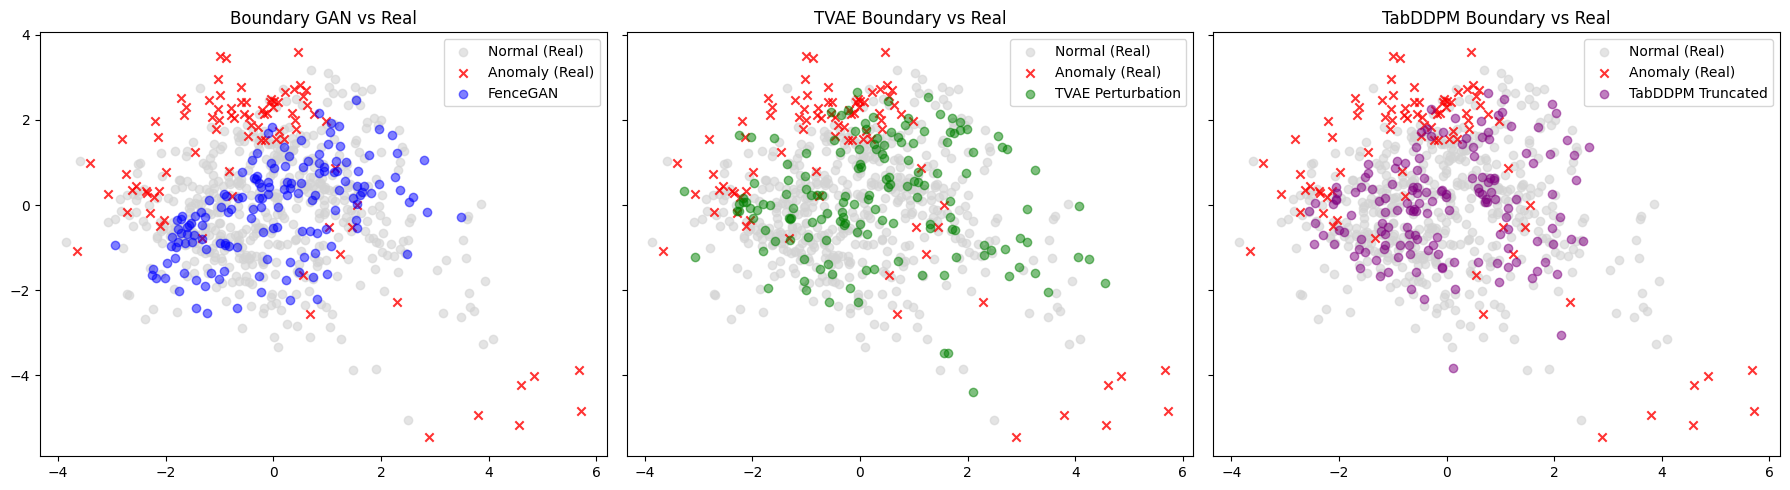

In [38]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=SEED)
pca.fit(X_train_proc)

norm_2d = pca.transform(X_train_normal[:500])
ano_real_2d = pca.transform(X_test_anomaly)
gan_2d = pca.transform(syn_gan[:200])
tvae_2d = pca.transform(syn_tvae[:200])
ddpm_2d = pca.transform(syn_ddpm[:200])

fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharex=True, sharey=True)

# Plot GAN
axes[0].scatter(norm_2d[:, 0], norm_2d[:, 1], c='lightgray', alpha=0.6, label='Normal (Real)')
axes[0].scatter(ano_real_2d[:, 0], ano_real_2d[:, 1], c='red', marker='x', alpha=0.8, label='Anomaly (Real)')
axes[0].scatter(gan_2d[:, 0], gan_2d[:, 1], c='blue', alpha=0.5, label='FenceGAN')
axes[0].set_title("Boundary GAN vs Real")
axes[0].legend()

# Plot TVAE
axes[1].scatter(norm_2d[:, 0], norm_2d[:, 1], c='lightgray', alpha=0.6, label='Normal (Real)')
axes[1].scatter(ano_real_2d[:, 0], ano_real_2d[:, 1], c='red', marker='x', alpha=0.8, label='Anomaly (Real)')
axes[1].scatter(tvae_2d[:, 0], tvae_2d[:, 1], c='green', alpha=0.5, label='TVAE Perturbation')
axes[1].set_title("TVAE Boundary vs Real")
axes[1].legend()

# Plot DDPM
axes[2].scatter(norm_2d[:, 0], norm_2d[:, 1], c='lightgray', alpha=0.6, label='Normal (Real)')
axes[2].scatter(ano_real_2d[:, 0], ano_real_2d[:, 1], c='red', marker='x', alpha=0.8, label='Anomaly (Real)')
axes[2].scatter(ddpm_2d[:, 0], ddpm_2d[:, 1], c='purple', alpha=0.5, label='TabDDPM Truncated')
axes[2].set_title("TabDDPM Boundary vs Real")
axes[2].legend()

plt.tight_layout()
plt.show()
